# Sales & Business Performance Analytics — EDA
**Role:** Member 3 — Exploratory Data Analysis  
**Dataset:** `data/raw/superstore_dataset2011-2015.csv`

## Objective
Inspect data quality, validate dates, calculate baseline KPIs, and explore sales and profit patterns. This notebook does not overwrite the raw CSV. Original date strings are retained; parsed dates are stored in separate columns.

## 1. Imports and locate the dataset

In [ ]:
%pip install numpy
%pip install pandas
%pip install matplotlib.pyplot
%pip install seaborn

In [7]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "notebooks" else cwd
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "superstore_dataset2011-2015.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Open this notebook from the project root or notebooks folder, "
        "or update DATA_PATH to your CSV location."
    )

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATA_PATH)

Project root: c:\Users\anshr\OneDrive\Desktop\sales-business-analytics
Dataset: c:\Users\anshr\OneDrive\Desktop\sales-business-analytics\data\raw\superstore_dataset2011-2015.csv


## 2. Load raw data

In [8]:
# df = pd.read_csv(DATA_PATH)


df = pd.read_csv(DATA_PATH, encoding="cp1252")

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
display(df.head())

Rows: 51,290
Columns: 24


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,Country,Postal Code,Market,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,42433,AG-2011-2040,1/1/2011,6/1/2011,Standard Class,TB-11280,Toby Braunhardt,Consumer,Constantine,Constantine,Algeria,NaN,Africa,Africa,OFF-TEN-10000025,Office Supplies,Storage,"Tenex Lockers, Blue",408.300,2,0.0,106.140,35.46,Medium
1,22253,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,JH-15985,Joseph Holt,Consumer,Wagga Wagga,New South Wales,Australia,NaN,APAC,Oceania,OFF-SU-10000618,Office Supplies,Supplies,"Acme Trimmer, High Speed",120.366,3,0.1,36.036,9.72,Medium
2,48883,HU-2011-1220,1/1/2011,5/1/2011,Second Class,AT-735,Annie Thurman,Consumer,Budapest,Budapest,Hungary,NaN,EMEA,EMEA,OFF-TEN-10001585,Office Supplies,Storage,"Tenex Box, Single Width",66.120,4,0.0,29.640,8.17,High
3,11731,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,EM-14140,Eugene Moren,Home Office,Stockholm,Stockholm,Sweden,NaN,EU,North,OFF-PA-10001492,Office Supplies,Paper,"Enermax Note Cards, Premium",44.865,3,0.5,-26.055,4.82,High
4,22255,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,JH-15985,Joseph Holt,Consumer,Wagga Wagga,New South Wales,Australia,NaN,APAC,Oceania,FUR-FU-10003447,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",113.670,5,0.1,37.770,4.70,Medium


## 3. Dataset structure

In [9]:
print("Columns:")
for column in df.columns:
    print("-", column)
print("\nData types and non-null counts:")
df.info()
display(df.describe(include="all").T)

Columns:
- Row ID
- Order ID
- Order Date
- Ship Date
- Ship Mode
- Customer ID
- Customer Name
- Segment
- City
- State
- Country
- Postal Code
- Market
- Region
- Product ID
- Category
- Sub-Category
- Product Name
- Sales
- Quantity
- Discount
- Profit
- Shipping Cost
- Order Priority

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          51290 non-null  int64  
 1   Order ID        51290 non-null  object 
 2   Order Date      51290 non-null  object 
 3   Ship Date       51290 non-null  object 
 4   Ship Mode       51290 non-null  object 
 5   Customer ID     51290 non-null  object 
 6   Customer Name   51290 non-null  object 
 7   Segment         51290 non-null  object 
 8   City            51290 non-null  object 
 9   State           51290 non-null  object 
 10  Country         51290 no

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,51290.0,NaN,NaN,NaN,25645.5,14806.29199,1.0,12823.25,25645.5,38467.75,51290.0
Order ID,51290,25035,CA-2014-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,51290,1430,18-06-2014,135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,51290,1464,22-11-2014,130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,51290,4,Standard Class,30775,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,51290,1590,PO-18850,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,51290,795,Muhammed Yedwab,108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,51290,3,Consumer,26518,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,51290,3636,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,51290,1094,California,2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data quality

In [10]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})
missing_summary = missing_summary[missing_summary["missing_count"] > 0].sort_values(
    "missing_count", ascending=False
)

print("Total exact duplicate rows:", df.duplicated().sum())
print("\nColumns with missing values:")
display(missing_summary)
for col in ["Order ID", "Customer ID", "Product ID"]:
    if col in df.columns:
        print(f"Unique {col}: {df[col].nunique():,}")
print("\nRepeated order/customer IDs can be normal in transaction data.")
print("Do not automatically remove missing postal codes or negative profits.")

Total exact duplicate rows: 0

Columns with missing values:


,missing_count,missing_percent
Postal Code,41296,80.51


Unique Order ID: 25,035
Unique Customer ID: 1,590
Unique Product ID: 10,292

Repeated order/customer IDs can be normal in transaction data.
Do not automatically remove missing postal codes or negative profits.


## 5. Parse and validate dates

The investigation found slash-separated and hyphen-separated dates. Use `dayfirst=True` with mixed-format parsing, while retaining the original strings. A successful check supports this interpretation but does not prove every source date is historically correct.

In [11]:
required_dates = ["Order Date", "Ship Date"]
missing_columns = [c for c in required_dates if c not in df.columns]
if missing_columns:
    raise KeyError(f"Missing required date columns: {missing_columns}")

row_count_before = len(df)
df["Order Date Parsed"] = pd.to_datetime(
    df["Order Date"], format="mixed", dayfirst=True, errors="coerce"
)
df["Ship Date Parsed"] = pd.to_datetime(
    df["Ship Date"], format="mixed", dayfirst=True, errors="coerce"
)

order_unparsed = int(df["Order Date Parsed"].isna().sum())
ship_unparsed = int(df["Ship Date Parsed"].isna().sum())
shipping_before_order = int(
    (df["Ship Date Parsed"] < df["Order Date Parsed"]).sum()
)

print("Rows:", len(df))
print("Unparsed order dates:", order_unparsed)
print("Unparsed ship dates:", ship_unparsed)
print("Shipping dates before order dates:", shipping_before_order)
print("Order date range:", df["Order Date Parsed"].min(), "to", df["Order Date Parsed"].max())
print("Ship date range:", df["Ship Date Parsed"].min(), "to", df["Ship Date Parsed"].max())

assert len(df) == row_count_before, "Unexpected row-count change."
assert order_unparsed == 0, "Investigate unparsed order dates before continuing."
assert ship_unparsed == 0, "Investigate unparsed ship dates before continuing."
assert shipping_before_order == 0, "Investigate date interpretation before continuing."
print("Date validation passed.")

Rows: 51290
Unparsed order dates: 0
Unparsed ship dates: 0
Shipping dates before order dates: 0
Order date range: 2011-01-01 00:00:00 to 2014-12-31 00:00:00
Ship date range: 2011-01-03 00:00:00 to 2015-01-07 00:00:00
Date validation passed.


## 6. Numeric summaries and distributions

,count,mean,std,min,25%,50%,75%,max
Row ID,51290.0,25645.500000,14806.291990,1.000,12823.250000,25645.500,38467.7500,51290.000
Postal Code,9994.0,55190.379428,32063.693350,1040.000,23223.000000,56430.500,90008.0000,99301.000
Sales,51290.0,246.490581,487.565361,0.444,30.758625,85.053,251.0532,22638.480
Quantity,51290.0,3.476545,2.278766,1.000,2.000000,3.000,5.0000,14.000
Discount,51290.0,0.142908,0.212280,0.000,0.000000,0.000,0.2000,0.850
Profit,51290.0,28.610982,174.340972,-6599.978,0.000000,9.240,36.8100,8399.976
Shipping Cost,51290.0,26.375915,57.296804,0.000,2.610000,7.790,24.4500,933.570


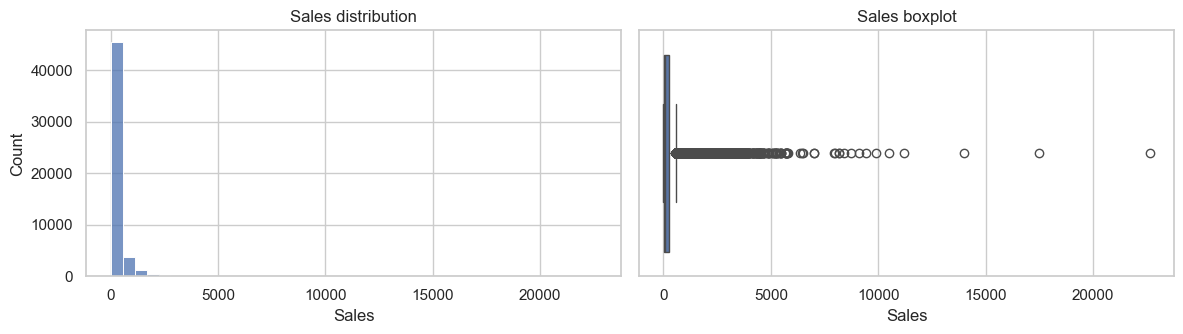

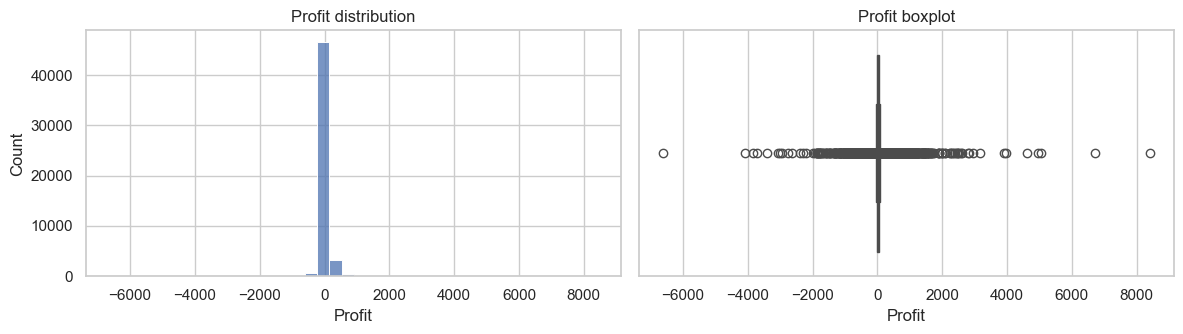

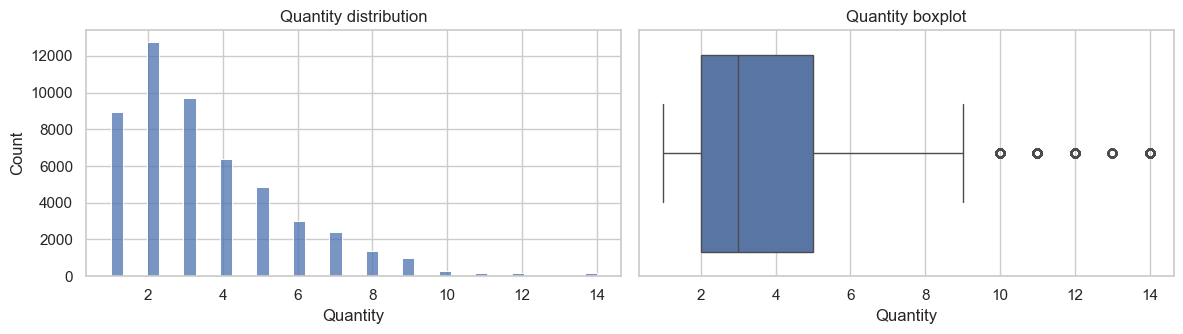

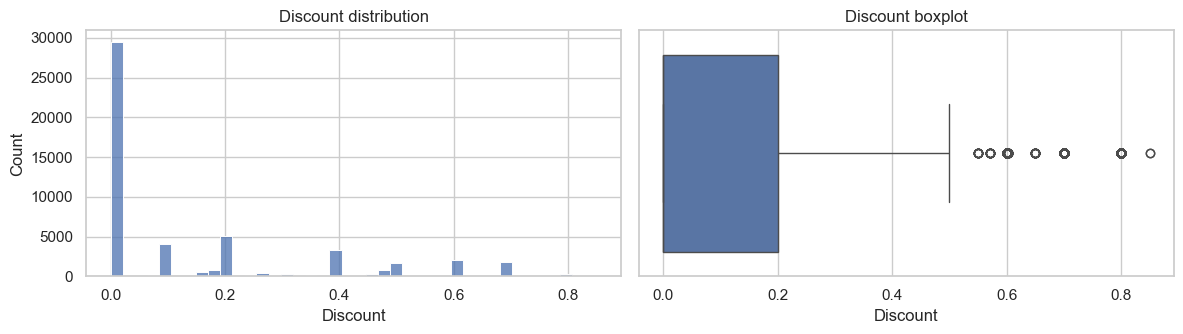

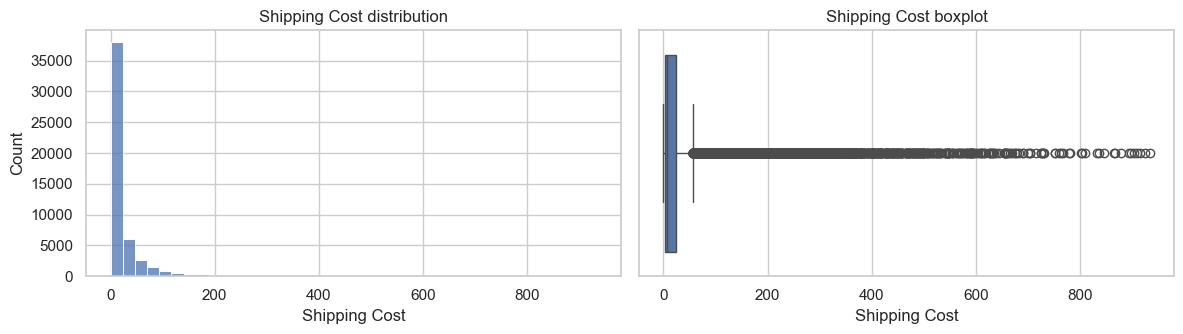

Treat unusual values as items to investigate, not automatic errors.


In [12]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_cols].describe().T)

for col in [c for c in ["Sales", "Profit", "Quantity", "Discount", "Shipping Cost"] if c in df.columns]:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    sns.histplot(df[col].dropna(), bins=40, ax=axes[0])
    axes[0].set_title(f"{col} distribution")
    sns.boxplot(x=df[col], ax=axes[1])
    axes[1].set_title(f"{col} boxplot")
    plt.tight_layout()
    plt.show()

print("Treat unusual values as items to investigate, not automatic errors.")

## 7. Baseline business KPIs

In [13]:
required = ["Sales", "Profit", "Quantity", "Order ID", "Customer ID"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Missing KPI columns: {missing}")

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
unique_orders = df["Order ID"].nunique()
unique_customers = df["Customer ID"].nunique()
aov = total_sales / unique_orders if unique_orders else np.nan
margin = total_profit / total_sales * 100 if total_sales else np.nan

kpi_summary = pd.DataFrame({
    "Metric": ["Total Sales", "Total Profit", "Total Quantity", "Unique Orders",
               "Unique Customers", "Average Order Value", "Profit Margin (%)"],
    "Value": [total_sales, total_profit, df["Quantity"].sum(), unique_orders,
              unique_customers, aov, margin]
})
display(kpi_summary)
print("Confirm currency conventions before external reporting.")

,Metric,Value
0,Total Sales,1.264250e+07
1,Total Profit,1.467457e+06
2,Total Quantity,1.783120e+05
3,Unique Orders,2.503500e+04
4,Unique Customers,1.590000e+03
5,Average Order Value,5.049931e+02
6,Profit Margin (%),1.160733e+01


Confirm currency conventions before external reporting.


## 8. Category and sub-category performance

,Sales,Profit,Quantity,Records
Category,,,,
Technology,4.744557e+06,663778.73318,35176,10141
Furniture,4.110874e+06,285204.72380,34954,9876
Office Supplies,3.787070e+06,518473.83430,108182,31273


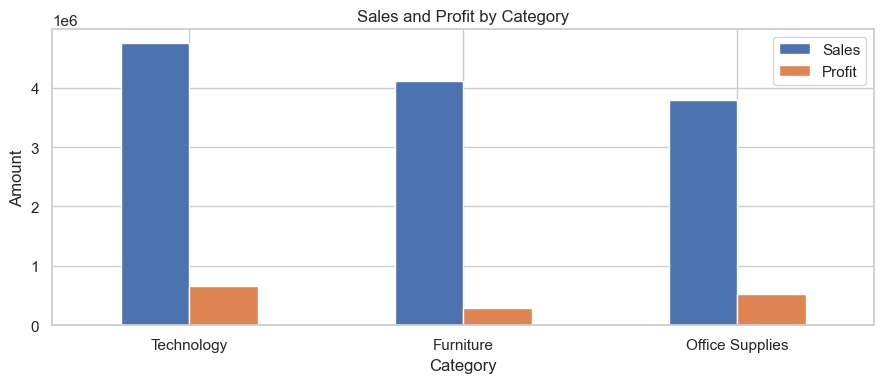

,Sales,Profit
Sub-Category,,
Phones,1.706824e+06,216717.00580
Copiers,1.509436e+06,258567.54818
Chairs,1.501682e+06,140396.26750
Bookcases,1.466572e+06,161924.41950
Storage,1.127086e+06,108461.48980
Appliances,1.011064e+06,141680.58940
Machines,7.790601e+05,58867.87300
Tables,7.570419e+05,-64083.38870
Accessories,7.492370e+05,129626.30620


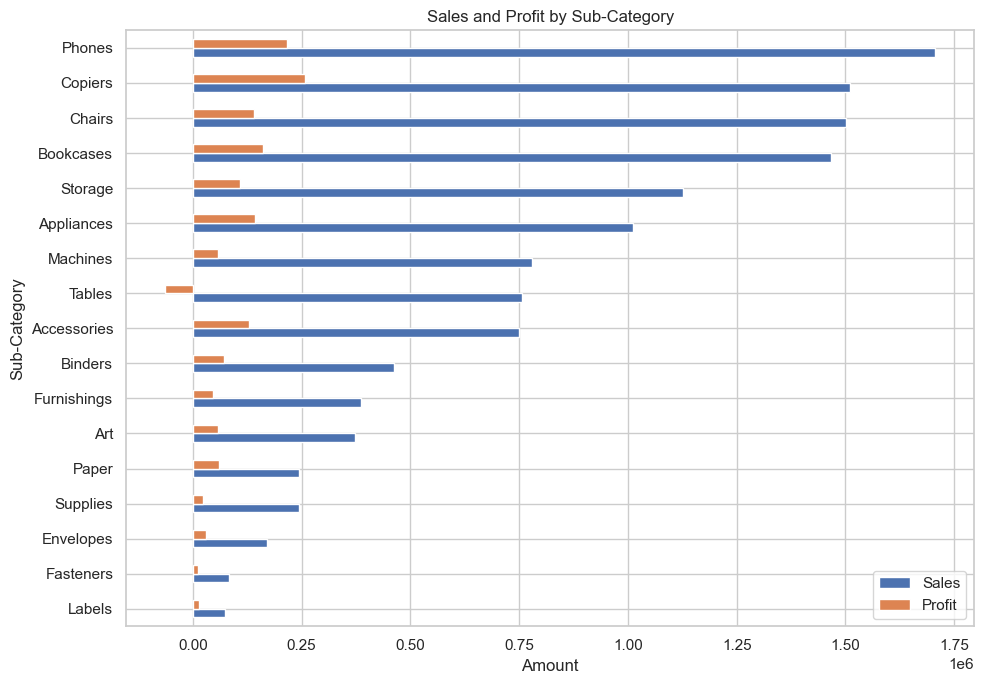

In [14]:
if {"Category", "Sales", "Profit", "Quantity"}.issubset(df.columns):
    category_perf = df.groupby("Category", dropna=False).agg(
        Sales=("Sales", "sum"), Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"), Records=("Category", "size")
    ).sort_values("Sales", ascending=False)
    display(category_perf)
    category_perf[["Sales", "Profit"]].plot(kind="bar", figsize=(9, 4))
    plt.title("Sales and Profit by Category")
    plt.ylabel("Amount")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

if {"Sub-Category", "Sales", "Profit"}.issubset(df.columns):
    subcategory_perf = df.groupby("Sub-Category", dropna=False).agg(
        Sales=("Sales", "sum"), Profit=("Profit", "sum")
    ).sort_values("Sales", ascending=False)
    display(subcategory_perf)
    subcategory_perf[["Sales", "Profit"]].sort_values("Sales").plot(
        kind="barh", figsize=(10, 7)
    )
    plt.title("Sales and Profit by Sub-Category")
    plt.xlabel("Amount")
    plt.tight_layout()
    plt.show()

## 9. Market, region, country, segment, shipping, and priority


Performance by Market:


,Sales,Profit,Records
Market,,,
APAC,3.585744e+06,436000.04900,11002
EU,2.938089e+06,372829.74150,10000
US,2.297201e+06,286397.02170,9994
LATAM,2.164605e+06,221643.48708,10294
EMEA,8.061613e+05,43897.97100,5029
Africa,7.837732e+05,88871.63100,4587
Canada,6.692817e+04,17817.39000,384


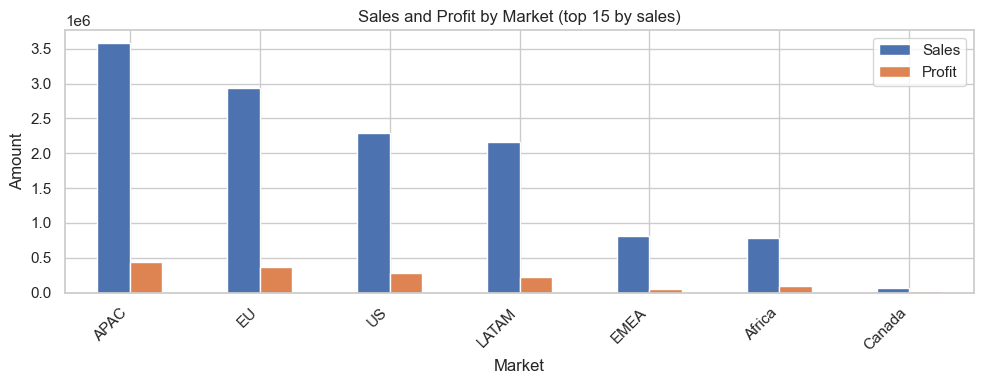


Performance by Region:


,Sales,Profit,Records
Region,,,
Central,2.822303e+06,311403.98164,11117
South,1.600907e+06,140355.76618,6645
North,1.248166e+06,194597.95252,4785
Oceania,1.100185e+06,120089.11200,3487
Southeast Asia,8.844232e+05,17852.32900,3129
North Asia,8.483098e+05,165578.42100,2338
EMEA,8.061613e+05,43897.97100,5029
Africa,7.837732e+05,88871.63100,4587
Central Asia,7.528266e+05,132480.18700,2048


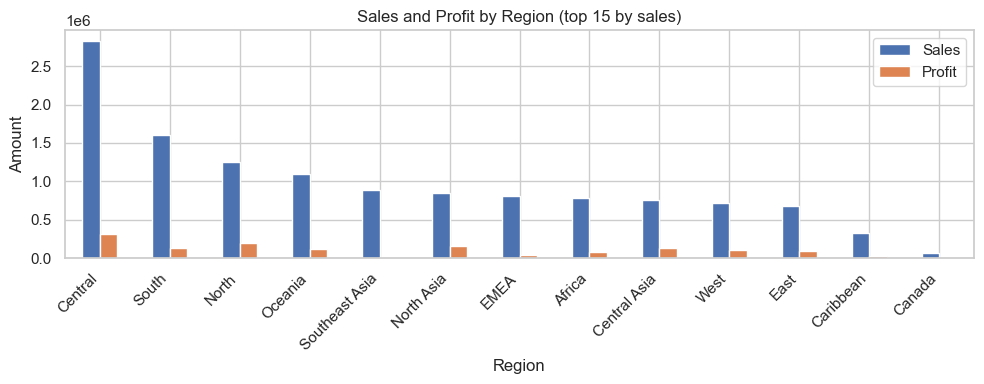


Performance by Country:


,Sales,Profit,Records
Country,,,
United States,2.297201e+06,286397.02170,9994
Australia,9.252359e+05,103907.43300,2837
France,8.589311e+05,109029.00300,2827
China,7.005620e+05,150683.08500,1880
Germany,6.288400e+05,107322.82050,2065
Mexico,6.225906e+05,102818.09752,2644
India,5.896501e+05,129071.83500,1555
United Kingdom,5.285763e+05,111900.15000,1633
Indonesia,4.048875e+05,15608.67790,1390


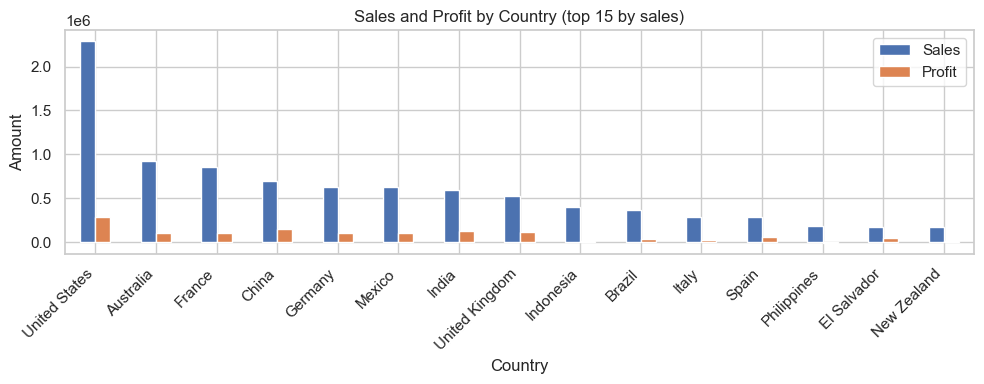


Performance by Segment:


,Sales,Profit,Records
Segment,,,
Consumer,6.507949e+06,749239.78206,26518
Corporate,3.824698e+06,441208.32866,15429
Home Office,2.309855e+06,277009.18056,9343


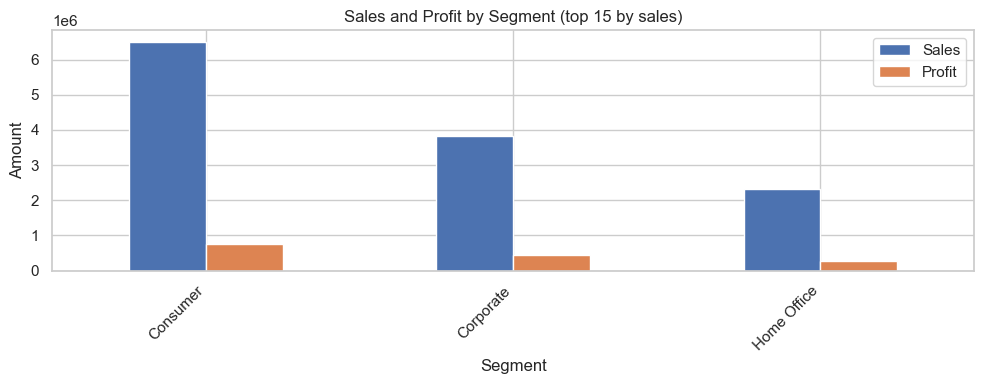


Performance by Ship Mode:


,Sales,Profit,Records
Ship Mode,,,
Standard Class,7.578652e+06,890596.02120,30775
Second Class,2.565672e+06,292583.52708,10309
First Class,1.830976e+06,208104.67520,7505
Same Day,6.672020e+05,76173.06780,2701


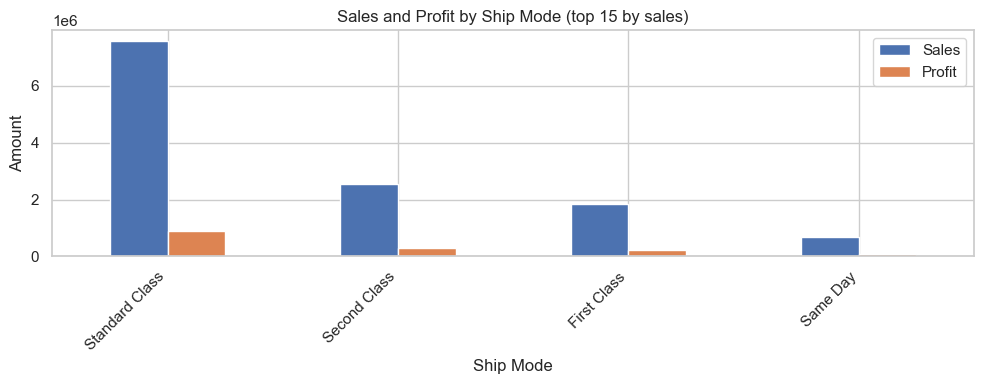


Performance by Order Priority:


,Sales,Profit,Records
Order Priority,,,
Medium,7.280892e+06,864203.76262,29433
High,3.807548e+06,420373.51340,15501
Critical,9.862355e+05,124224.16428,3932
Low,5.678259e+05,58655.85098,2424


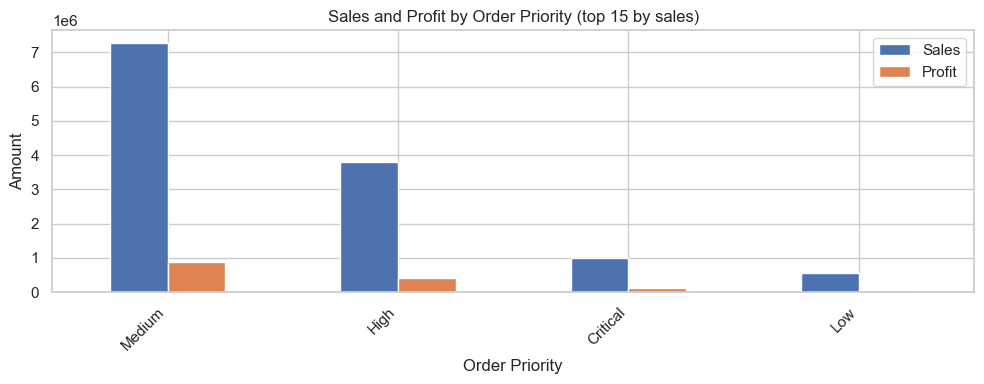

In [15]:
for col in ["Market", "Region", "Country", "Segment", "Ship Mode", "Order Priority"]:
    if col in df.columns:
        summary = df.groupby(col, dropna=False).agg(
            Sales=("Sales", "sum"), Profit=("Profit", "sum"), Records=(col, "size")
        ).sort_values("Sales", ascending=False)
        print(f"\nPerformance by {col}:")
        display(summary.head(20))
        summary[["Sales", "Profit"]].head(15).plot(kind="bar", figsize=(10, 4))
        plt.title(f"Sales and Profit by {col} (top 15 by sales)")
        plt.ylabel("Amount")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

## 10. Customer and product analysis

In [16]:
if {"Customer ID", "Sales", "Profit", "Order ID"}.issubset(df.columns):
    customer_perf = df.groupby("Customer ID", dropna=False).agg(
        Sales=("Sales", "sum"), Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique")
    ).sort_values("Sales", ascending=False)
    print("Top 10 customers by sales:")
    display(customer_perf.head(10))

if {"Product Name", "Sales", "Profit", "Quantity"}.issubset(df.columns):
    product_perf = df.groupby("Product Name", dropna=False).agg(
        Sales=("Sales", "sum"), Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum")
    ).sort_values("Sales", ascending=False)
    print("Top 10 products by sales:")
    display(product_perf.head(10))

Top 10 customers by sales:


,Sales,Profit,Orders
Customer ID,,,
TA-21385,35668.12080,6274.98910,25
GT-14710,34471.89028,5164.84718,30
TC-20980,34218.26900,8787.47490,28
SM-20320,31125.29496,-1083.67434,21
BW-11110,30613.61650,3337.46590,35
HL-15040,29664.23058,7657.50178,20
SE-20110,29532.62502,5863.62392,36
PS-19045,29252.31940,4426.19510,26
RB-19360,29197.63460,8523.95150,25


Top 10 products by sales:


,Sales,Profit,Quantity
Product Name,,,
"Apple Smart Phone, Full Size",86935.7786,5921.5786,171
"Cisco Smart Phone, Full Size",76441.5306,17238.5206,139
"Motorola Smart Phone, Full Size",73156.3030,17027.1130,134
"Nokia Smart Phone, Full Size",71904.5555,9938.1955,147
Canon imageCLASS 2200 Advanced Copier,61599.8240,25199.9280,20
"Hon Executive Leather Armchair, Adjustable",58193.4841,5997.2541,169
"Office Star Executive Leather Armchair, Adjustable",50661.6840,4710.9840,141
"Harbour Creations Executive Leather Armchair, Adjustable",50121.5160,10427.3260,142
"Samsung Smart Phone, Cordless",48653.4600,-198.0900,108


## 11. Monthly and yearly trends

First months:


,Sales,Profit,Orders
Order Month,,,
2011-01-01,98898.48886,8321.80096,216
2011-02-01,91152.15698,12417.90698,183
2011-03-01,145729.36736,15303.56826,277
2011-04-01,116915.76418,12902.32438,267
2011-05-01,146747.83610,12183.82870,295


Last months:


,Sales,Profit,Orders
Order Month,,,
2014-08-01,456619.94236,53542.89496,843
2014-09-01,481157.24370,67979.45110,1017
2014-10-01,422766.62916,58209.83476,810
2014-11-01,555279.02700,62856.58790,1077
2014-12-01,503143.69348,46916.52068,1093


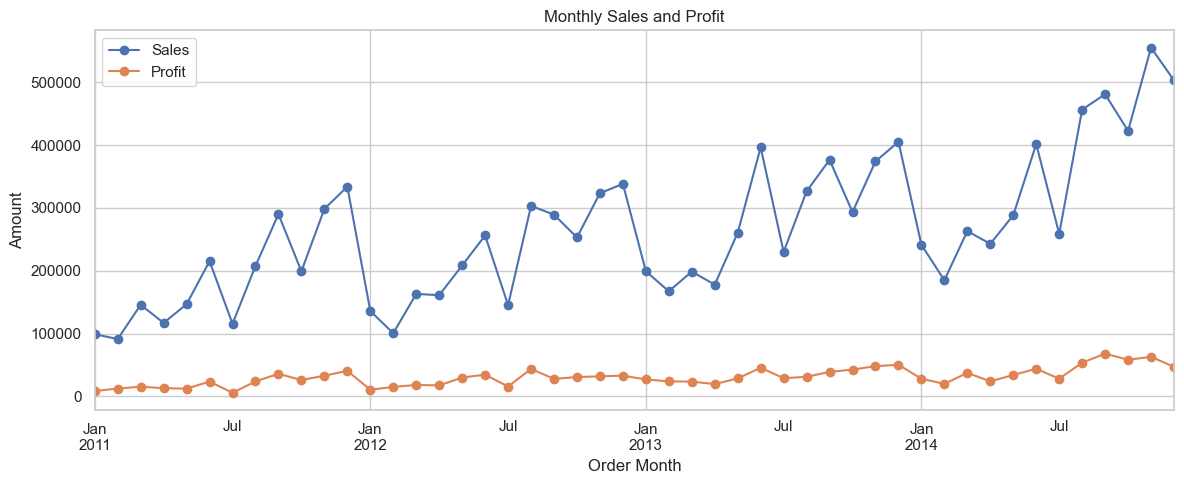

,Sales,Profit,Orders
Order Year,,,
2011,2.259451e+06,248940.81154,4440
2012,2.677439e+06,307415.27910,5343
2013,3.405746e+06,406935.23018,6721
2014,4.299866e+06,504165.97046,8531


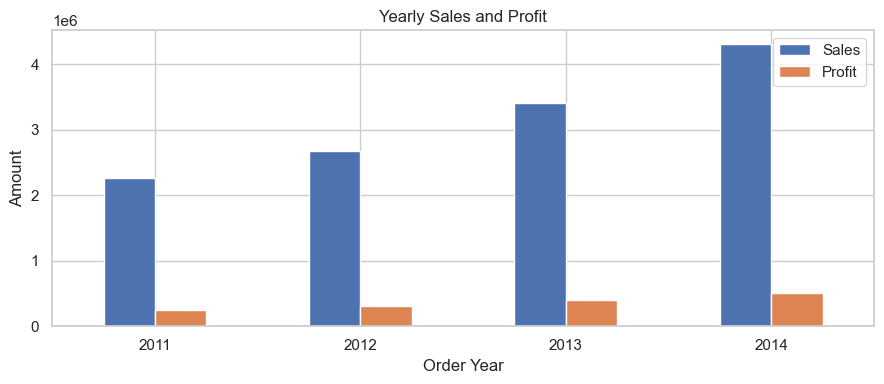

In [17]:
trend_df = df.dropna(subset=["Order Date Parsed"]).copy()
trend_df["Order Month"] = trend_df["Order Date Parsed"].dt.to_period("M").dt.to_timestamp()
trend_df["Order Year"] = trend_df["Order Date Parsed"].dt.year

monthly_perf = trend_df.groupby("Order Month").agg(
    Sales=("Sales", "sum"), Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).sort_index()
print("First months:")
display(monthly_perf.head())
print("Last months:")
display(monthly_perf.tail())
monthly_perf[["Sales", "Profit"]].plot(figsize=(12, 5), marker="o")
plt.title("Monthly Sales and Profit")
plt.xlabel("Order Month")
plt.ylabel("Amount")
plt.tight_layout()
plt.show()

yearly_perf = trend_df.groupby("Order Year").agg(
    Sales=("Sales", "sum"), Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).sort_index()
display(yearly_perf)
yearly_perf[["Sales", "Profit"]].plot(kind="bar", figsize=(9, 4))
plt.title("Yearly Sales and Profit")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 12. Discount and profitability

,Records,Sales,Profit,Average_Profit
Discount,,,,
0.000,29009,6.992411e+06,1.770695e+06,61.039514
0.002,461,2.613956e+05,5.797658e+04,125.762649
0.070,150,1.216169e+05,2.114850e+04,140.990022
0.100,4068,1.579606e+06,2.590642e+05,63.683426
0.150,541,3.060298e+05,2.737590e+04,50.602409
0.170,735,2.473992e+05,2.816307e+04,38.317107
0.200,4998,1.203832e+06,1.177159e+05,23.552594
0.202,41,1.621565e+04,-5.952727e+02,-14.518847
0.250,198,8.805535e+04,8.005875e+02,4.043371


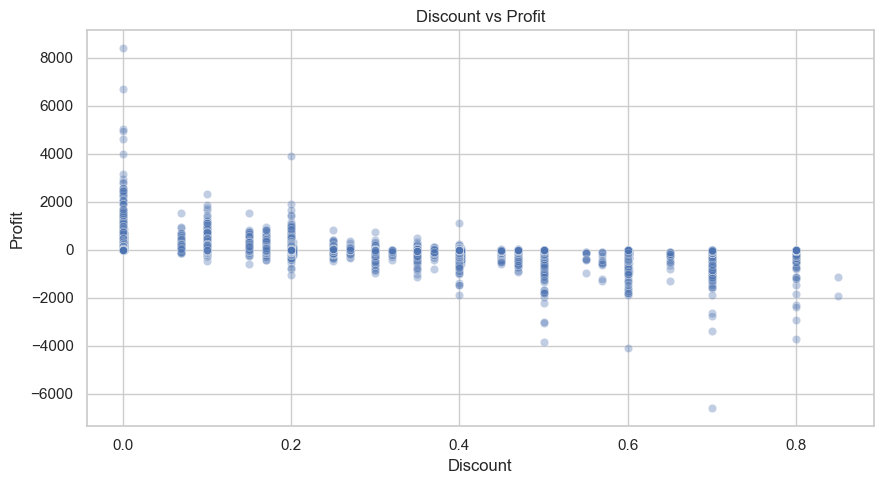

Observed association does not by itself establish causation.


In [18]:
if {"Discount", "Profit", "Sales"}.issubset(df.columns):
    discount_summary = df.groupby("Discount", dropna=False).agg(
        Records=("Profit", "size"), Sales=("Sales", "sum"),
        Profit=("Profit", "sum"), Average_Profit=("Profit", "mean")
    ).sort_index()
    display(discount_summary)
    plt.figure(figsize=(9, 5))
    sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.35)
    plt.title("Discount vs Profit")
    plt.tight_layout()
    plt.show()
    print("Observed association does not by itself establish causation.")

## 13. Findings to document after reviewing outputs

Write only findings supported by the tables and charts:
- highest-sales and highest-profit category/sub-category;
- strongest and weakest market or region;
- visible monthly/yearly trends;
- discount levels associated with lower or higher observed profit;
- data-quality limitations, including missing postal codes and mixed date strings.

Avoid claiming causation from descriptive analysis alone.

## 14. Optional export of summary tables

In [19]:
EXPORT_SUMMARIES = False  # Change to True if you want CSV summary files.

if EXPORT_SUMMARIES:
    reports_dir = PROJECT_ROOT / "reports"
    reports_dir.mkdir(parents=True, exist_ok=True)
    kpi_summary.to_csv(reports_dir / "eda_baseline_kpis.csv", index=False)
    if "category_perf" in globals():
        category_perf.to_csv(reports_dir / "eda_category_performance.csv")
    if "monthly_perf" in globals():
        monthly_perf.to_csv(reports_dir / "eda_monthly_performance.csv")
    print("Summary tables exported to:", reports_dir)
else:
    print("Export disabled; no files written.")

Export disabled; no files written.
